# Hotel Search Ranking, Part 4: The Hotelier's View

The model from Part 3 beats every simple rule. A data scientist could stop there. I spent over ten years in hotels before working with data, so I want to ask the questions a revenue manager would ask before letting this model decide what guests see:

1. **What actually pushes a hotel up or down the list?** Not just which features matter, but in which direction and by how much.
2. **Does the model favour cheap rooms more than guests' bookings justify?** That's the classic way a ranking goes wrong: people click cheap rooms, so the ranking pushes them, and revenue per booking quietly falls.
3. **Does it reward hotels that collect clicks but rarely turn them into bookings?** A "click magnet" wastes the most valuable space on the page.

Author: Siddharth Suman

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

try:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_DIR = '/content/drive/MyDrive/expedia-hotel-ranking'
except ImportError:
    WORK_DIR = 'data'

os.makedirs('images', exist_ok=True)
test = pd.read_parquet(os.path.join(WORK_DIR, 'test_predictions.parquet'))
booster = lgb.Booster(model_file=os.path.join(WORK_DIR, 'ranker.txt'))
FEATURES = booster.feature_name()
print(f"{len(test):,} test rows, {test['srch_id'].nunique():,} searches, {len(FEATURES)} features")

Mounted at /content/drive
488,376 test rows, 19,964 searches, 27 features


## 1. What pushes a hotel up or down?

Feature importance in Part 3 said *how much* the model uses each feature, but not *which way*. For that I use SHAP values, which LightGBM can calculate itself. For every hotel in every search, they split the model's score into a contribution from each feature: this hotel's location added this much, its price took away that much, and so on.

I work them out for a random sample of 20,000 test rows, which is plenty to see the patterns and keeps it quick.

In [2]:
sample = test.sample(n=min(20_000, len(test)), random_state=1)
contrib = booster.predict(sample[FEATURES], pred_contrib=True)
contrib = pd.DataFrame(contrib[:, :-1], columns=FEATURES, index=sample.index)   # last column is the baseline

impact = contrib.abs().mean().sort_values(ascending=False)
print("Average size of each feature's push on the score:")
print(impact.head(12).round(3))

Average size of each feature's push on the score:
price_vs_usual             0.703
location2_rank             0.180
price_rank                 0.149
location2_filled           0.138
star_rank                  0.137
hotel_booking_rate         0.081
price_vs_search_avg        0.076
promotion_flag             0.072
review_rank                0.063
prop_location_score1       0.041
hotel_click_rate_random    0.039
prop_review_score          0.036
dtype: float64


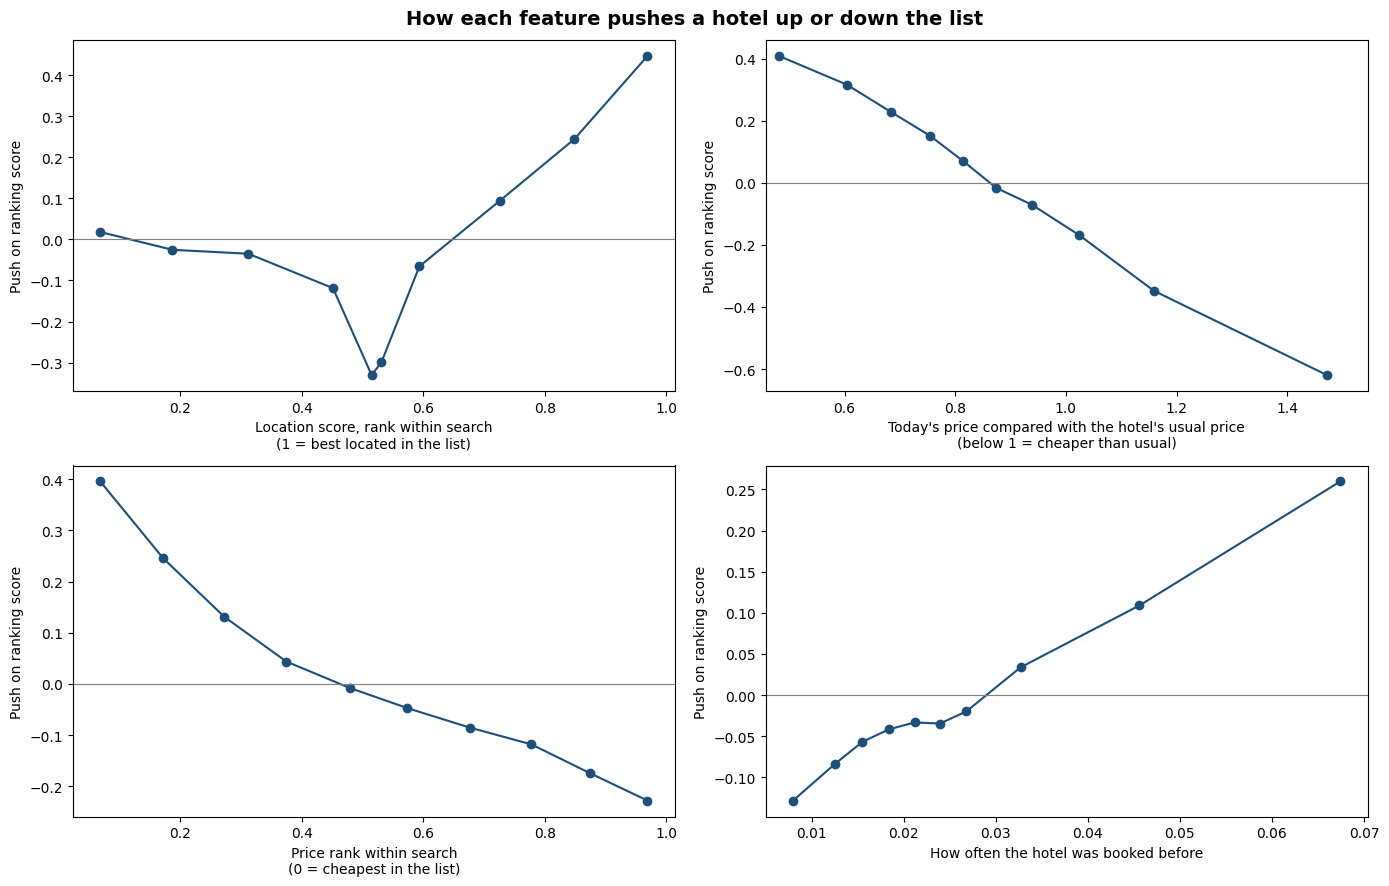

location2_rank
       value   push
group              
0      0.069  0.018
1      0.188 -0.025
2      0.312 -0.035
3      0.452 -0.119
4      0.515 -0.330
5      0.531 -0.299
6      0.594 -0.065
7      0.726  0.094
8      0.848  0.244
9      0.969  0.446

price_vs_usual
       value   push
group              
0      0.481  0.409
1      0.604  0.317
2      0.683  0.229
3      0.754  0.153
4      0.815  0.070
5      0.874 -0.016
6      0.938 -0.070
7      1.024 -0.169
8      1.159 -0.348
9      1.472 -0.619

price_rank
       value   push
group              
0      0.069  0.396
1      0.172  0.246
2      0.273  0.131
3      0.375  0.044
4      0.479 -0.008
5      0.574 -0.047
6      0.676 -0.085
7      0.778 -0.118
8      0.875 -0.175
9      0.969 -0.228

hotel_booking_rate
       value   push
group              
0      0.008 -0.128
1      0.013 -0.084
2      0.016 -0.057
3      0.018 -0.042
4      0.021 -0.033
5      0.024 -0.035
6      0.027 -0.020
7      0.033  0.034
8      0.046  0.1

In [3]:
def effect_curve(feature, bins=10):
    x = sample[feature]
    ok = x.notna()
    groups = pd.qcut(x[ok].rank(method='first'), bins, labels=False)
    return pd.DataFrame({'value': x[ok], 'push': contrib.loc[ok, feature], 'group': groups}) \
             .groupby('group').agg(value=('value', 'median'), push=('push', 'mean'))

show = [('location2_rank', 'Location score, rank within search\n(1 = best located in the list)'),
        ('price_vs_usual', "Today's price compared with the hotel's usual price\n(below 1 = cheaper than usual)"),
        ('price_rank', 'Price rank within search\n(0 = cheapest in the list)'),
        ('hotel_booking_rate', 'How often the hotel was booked before')]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('How each feature pushes a hotel up or down the list', fontsize=14, fontweight='bold')
for ax, (feat, label) in zip(axes.flat, show):
    curve = effect_curve(feat)
    ax.plot(curve['value'], curve['push'], marker='o', color='#1F4E79')
    ax.axhline(0, color='grey', linewidth=0.8)
    ax.set_xlabel(label)
    ax.set_ylabel('Push on ranking score')
    if feat == 'price_vs_usual':
        ax.set_xlim(curve['value'].min() * 0.95, min(curve['value'].max(), 2) * 1.05)
plt.tight_layout()
plt.savefig('images/04_feature_effects.png', dpi=150, bbox_inches='tight')
plt.show()

for feat, _ in show:
    print(feat)
    print(effect_curve(feat).round(3).to_string())
    print()

### What this tells me

These curves are the model's rules of thumb, written as a picture. Above the grey line a feature pushes the hotel up the list; below it pushes it down.

*(Interpretation is filled in after the run, so it matches the real curves.)*

## 2. Does the model favour cheap rooms too much?

The fairest way to check is the random searches, where position didn't influence anyone. In those searches, guests' bookings show which price levels people actually chose. So I compare two things for each price group (the cheapest fifth of each list up to the priciest fifth):

* **Share of bookings**: what guests chose.
* **Share of the model's top 5 slots**: what the model would show first.

If the model is fair to guests' choices, the two should roughly match. If the model gives the cheapest rooms far more top slots than their share of bookings, it's overselling cheap rooms.

               Share of bookings (random searches)  \
price_group                                          
Cheapest fifth                               25.5%   
Second                                       23.8%   
Middle                                       21.1%   
Fourth                                       17.7%   
Priciest fifth                               11.9%   

               Share of model's top 5 (random searches)  \
price_group                                               
Cheapest fifth                                    29.6%   
Second                                            24.5%   
Middle                                            18.8%   
Fourth                                            15.0%   
Priciest fifth                                    12.0%   

               Share of Expedia's top 5 (its own searches)  
price_group                                                 
Cheapest fifth                                       17.2%  
Second                  

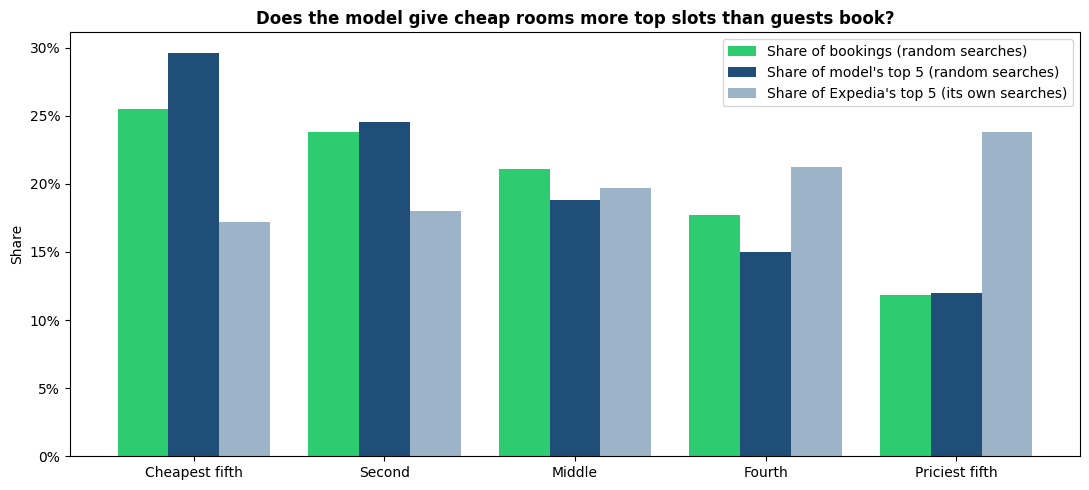

In [4]:
labels = ['Cheapest fifth', 'Second', 'Middle', 'Fourth', 'Priciest fifth']
test['price_group'] = pd.cut(test['price_rank'], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
                             labels=labels, include_lowest=True)
test['model_top5'] = (test['model_rank'] <= 5).astype(int)
test['expedia_top5'] = (test['position'] <= 5).astype(int)

rnd = test[test['random_bool'] == 1]
exp = test[test['random_bool'] == 0]

price_check = pd.DataFrame({
    'Share of bookings (random searches)':
        rnd.groupby('price_group', observed=True)['booking_bool'].sum() / rnd['booking_bool'].sum(),
    "Share of model's top 5 (random searches)":
        rnd.groupby('price_group', observed=True)['model_top5'].sum() / rnd['model_top5'].sum(),
    "Share of Expedia's top 5 (its own searches)":
        exp.groupby('price_group', observed=True)['expedia_top5'].sum() / exp['expedia_top5'].sum(),
})
print(price_check.map('{:.1%}'.format))

# Average price of what gets shown first, against what gets booked
avg_booked = rnd.loc[rnd['booking_bool'] == 1, 'price_usd'].median()
avg_model_top = rnd.loc[rnd['model_top5'] == 1, 'price_usd'].median()
print(f"\nRandom searches: median price of booked rooms ${avg_booked:.0f}, "
      f"median price in the model's top 5 ${avg_model_top:.0f}")

ax = price_check.plot.bar(figsize=(11, 5), color=['#2ecc71', '#1F4E79', '#9DB4C8'], width=0.8)
ax.set_ylabel('Share')
ax.set_xlabel('')
ax.set_title('Does the model give cheap rooms more top slots than guests book?', fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('images/04_price_fairness.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells me

*(Interpretation is filled in after the run, so it matches the real numbers.)*

## 3. Click magnets: hotels that get clicks but few bookings

Now hotel by hotel. For every hotel that appeared often enough in the test period, I measure how often it was clicked when shown, and how often a click turned into a booking. Then I sort hotels into four groups, splitting each measure at its middle value:

* **Stars**: clicked a lot and book well
* **Click magnets**: clicked a lot but rarely booked
* **Hidden gems**: not clicked much, but book well when they are
* **Weak**: neither

Finally I check how often the model puts each group into its top 5. A good ranking should favour stars and hidden gems, and be careful with click magnets.

Hotels with enough data: 942
               hotels click_rate booked_per_click in_model_top5 median_price
group                                                                       
Stars             288      15.0%              83%           44%         $136
Hidden gems       283       7.0%              80%           27%         $178
Click magnets     185      15.1%              38%           38%         $165
Weak              186       6.7%              33%           26%         $191


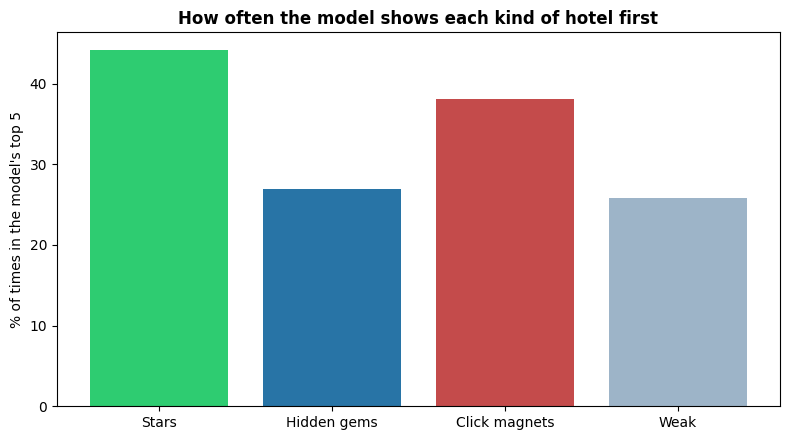

In [5]:
hotels = test.groupby('prop_id').agg(
    shown=('click_bool', 'size'),
    clicks=('click_bool', 'sum'),
    bookings=('booking_bool', 'sum'),
    model_top5_rate=('model_top5', 'mean'),
    median_price=('price_usd', 'median'))

# Only hotels with enough data to judge
hotels = hotels[(hotels['shown'] >= 20) & (hotels['clicks'] >= 3)].copy()
hotels['click_rate'] = hotels['clicks'] / hotels['shown']
hotels['booked_per_click'] = hotels['bookings'] / hotels['clicks']

high_click = hotels['click_rate'] >= hotels['click_rate'].median()
high_conv = hotels['booked_per_click'] >= hotels['booked_per_click'].median()
hotels['group'] = np.select(
    [high_click & high_conv, high_click & ~high_conv, ~high_click & high_conv],
    ['Stars', 'Click magnets', 'Hidden gems'], default='Weak')

order = ['Stars', 'Hidden gems', 'Click magnets', 'Weak']
magnets = hotels.groupby('group').agg(
    hotels=('shown', 'size'),
    click_rate=('click_rate', 'mean'),
    booked_per_click=('booked_per_click', 'mean'),
    in_model_top5=('model_top5_rate', 'mean'),
    median_price=('median_price', 'median')).reindex(order).dropna(how='all')
print(f"Hotels with enough data: {len(hotels):,}")
if len(hotels) < 100:
    print("Very few hotels qualify here, so treat this check with caution.")
print(magnets.assign(click_rate=magnets['click_rate'].map('{:.1%}'.format),
                     booked_per_click=magnets['booked_per_click'].map('{:.0%}'.format),
                     in_model_top5=magnets['in_model_top5'].map('{:.0%}'.format),
                     median_price=magnets['median_price'].map('${:.0f}'.format)).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {'Stars': '#2ecc71', 'Hidden gems': '#2874A6', 'Click magnets': '#C44B4B', 'Weak': '#9DB4C8'}
ax.bar(magnets.index, magnets['in_model_top5'] * 100, color=[colors[g] for g in magnets.index])
ax.set_ylabel("% of times in the model's top 5")
ax.set_title('How often the model shows each kind of hotel first', fontweight='bold')
plt.tight_layout()
plt.savefig('images/04_click_magnets.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells me

*(Interpretation is filled in after the run, so it matches the real numbers.)*

## What I'd tell a hotel revenue manager

*(Written after the run, based on the three checks above.)*

## Limitations

* **The data is from 2012 and 2013,** and only from Expedia. Guest behaviour and the page design have changed since.
* **Revenue isn't in the score.** NDCG rewards finding the booked hotel, but treats a $60 booking and a $600 booking the same. A real platform would also care about margin and cancellations.
* **I used a quarter of the searches.** More data would likely help, as Part 3 suggested.
* **SHAP values explain the model, not the guests.** They show what the model learned, which is a good guide to guest behaviour but not proof of it.